## 1. Wczytanie danych i funkcje pomocnicze

Osiem tabel jednego meczu z `output/` (używamy tylko `formations` i `team_stats`) oraz **wspólna tabela wszystkich meczów** `events_all`, na której pracują sekcje 2–7 i 12–14. Tu też funkcje używane dalej (Wilson, tabela warunkowa, R² płaszczyzny).


In [1]:
# Wczytanie: tabele JEDNEGO meczu (formacje, statystyki) + wspolna tabela wszystkich meczow
from pathlib import Path

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
DATA = ROOT / "output"
FIGURY = DATA / "figures"
FIGURY.mkdir(parents=True, exist_ok=True)

# jeden mecz - do wizualizacji per-mecz (sekcje 10-11)
MATCH = "match_1821123_Southampton_vs_Aston_Villa"

# wszystkie tabele, jakie produkuje scraper, trzymamy w jednym slowniku
tabele_meczu = {
    nazwa: pd.read_csv(DATA / f"{MATCH}_{nazwa}.csv")
    for nazwa in [
        "players",
        "metadata",
        "formations",
        "lookups",
        "minute_mapping",
        "player_stats",
        "shot_zones",
        "team_stats",
    ]
}

# dalej uzywamy tylko tych dwoch - reszta sluzy jako przeglad danych
formations = tabele_meczu["formations"]
team_stats = tabele_meczu["team_stats"]

print("mecz do wizualizacji:", MATCH)
for nazwa, tabela in tabele_meczu.items():
    print(f"  {nazwa:<16} {str(tabela.shape):>14}")


mecz do wizualizacji: match_1821123_Southampton_vs_Aston_Villa
  players                (40, 23)
  metadata                (1, 58)
  formations             (99, 21)
  lookups                (243, 3)
  minute_mapping         (100, 4)
  player_stats          (4785, 9)
  shot_zones              (27, 8)
  team_stats            (1462, 7)


In [2]:
# Wszystkie mecze w jednej tabeli - na niej pracuja sekcje 2-7 oraz 12-14
pliki = sorted(DATA.glob("*_events.csv"))

events_all = pd.concat([pd.read_csv(f) for f in pliki], ignore_index=True)

print("meczow:", len(pliki))
print("zdarzen razem:", len(events_all))
print("kolumn:", len(events_all.columns))
print()
print("zduplikowane wiersze:", events_all.duplicated().sum())
print("kolizje id          :", events_all["id"].duplicated().sum())


meczow: 10
zdarzen razem: 16249
kolumn: 95

zduplikowane wiersze: 0
kolizje id          : 4


In [3]:
# Funkcje pomocnicze uzywane w dalszych sekcjach (zdefiniowane raz, na gorze)
def wilson(k, n):
    """95% przedzial ufnosci Wilsona dla proporcji, w procentach."""
    if n == 0:
        return 0.0, 0.0
    z = 1.96
    p = k / n
    mian = 1 + z ** 2 / n
    srodek = (p + z ** 2 / (2 * n)) / mian
    polowa = z * ((p * (1 - p) / n + z ** 2 / (4 * n ** 2)) ** 0.5) / mian
    return 100 * (srodek - polowa), 100 * (srodek + polowa)


def tabela(dane, kolumna, cel="strzal"):
    """P(cel | kolumna) z 95% przedzialem ufnosci Wilsona."""
    t = dane.groupby(kolumna, observed=False).agg(
        przypadkow=(cel, "size"),
        trafien=(cel, "sum"),
    )
    t["P %"] = (100 * t["trafien"] / t["przypadkow"]).round(2)

    przedzialy = []
    for k, n in zip(t["trafien"], t["przypadkow"]):
        dol, gora = wilson(k, n)
        przedzialy.append(f"{dol:.1f}-{gora:.1f}")

    t["95% CI"] = przedzialy
    return t


def r2_plaszczyzny(dane, x1, x2, y):
    """R2 dopasowania plaszczyzny najmniejszych kwadratow y ~ x1 + x2."""
    X = np.column_stack([np.ones(len(dane)), dane[x1], dane[x2]])
    y_prawdziwe = dane[y].to_numpy()

    beta, *_ = np.linalg.lstsq(X, y_prawdziwe, rcond=None)
    y_pred = X @ beta

    ss_res = ((y_prawdziwe - y_pred) ** 2).sum()
    ss_tot = ((y_prawdziwe - y_prawdziwe.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


print("dostepne funkcje: wilson(), tabela(), r2_plaszczyzny()")


dostepne funkcje: wilson(), tabela(), r2_plaszczyzny()


## 2. Cechy przestrzenne

Kolumny pochodne dopisywane do `events_all`: dystans do bramki, pole karne, złota strefa, strzał celny.


In [4]:
# Cechy przestrzenne - KOLUMNY POCHODNE dopisywane do events_all (nie osobne tabele).
# Wartosci x, y sa w skali 0-100; bramka przeciwnika to punkt (100, 50).
events_all["dystans_do_bramki"] = np.hypot(100 - events_all["x"], 50 - events_all["y"])

# Pole karne: x >= 83 ORAZ y w [21, 79]. Samo x >= 83 lapie tez zdarzenia
# za linia koncowa po bokach (627 z 1306 takich zdarzen w jednym meczu).
events_all["w_polu"] = (events_all["x"] >= 83) & (events_all["y"].between(21, 79))

# Zlota strefa - bezposrednio przed bramka.
events_all["zlota_strefa"] = (events_all["x"] >= 88) & (events_all["y"].between(36, 64))

# Strzal celny: gol albo obrona bramkarza.
events_all["strzal_celny"] = events_all["event_type"].isin(["Goal", "SavedShot"])

print("dystans do bramki : min %.1f  max %.1f" % (
    events_all["dystans_do_bramki"].min(),
    events_all["dystans_do_bramki"].max(),
))
print("zdarzen w polu karnym   :", int(events_all["w_polu"].sum()))
print("zdarzen w zlotej strefie:", int(events_all["zlota_strefa"].sum()))
print("strzalow celnych        :", int(events_all["strzal_celny"].sum()))


dystans do bramki : min 0.9  max 111.8
zdarzen w polu karnym   : 690
zdarzen w zlotej strefie: 224
strzalow celnych        : 180


## 3. Selekcja kolumn do analizy zależności

Usuwa identyfikatory, flagi 0/1, kolumny o niskim pokryciu i duplikaty informacyjne.


In [5]:
# Selekcja kolumn do analizy zaleznosci (na wszystkich meczach)
# identyfikatory, kategorie i duplikaty informacyjne - bez sensu w korelacjach
POMIJANE = [
    "match_id", "event_index", "id", "event_id",
    "team_id", "player_id", "related_event_id",
    "opposite_related_event_id", "next_team_id", "next_player_id",
    "receiver_id", "minute", "shirt_no", "period_value",
    "event_field", "minute_info_minute", "minute_info_expanded_minute",
    "minute_info_period", "minute_info_extra_time",
]

MIN_POKRYCIE = 0.5

wybrane = []
for kol in events_all.select_dtypes("number").columns:
    if kol in POMIJANE:
        continue
    if events_all[kol].notna().mean() < MIN_POKRYCIE:
        continue
    if events_all[kol].dropna().isin([0, 1]).all():
        continue
    wybrane.append(kol)

# usun kolumny niosace te sama informacje (|r| > 0.99)
unikalne = []
for kol in wybrane:
    for kept in unikalne:
        if abs(events_all[kol].corr(events_all[kept])) > 0.99:
            print(f"  pomijam {kol}: to samo co {kept}")
            break
    else:
        unikalne.append(kol)

wybrane = unikalne

print()
print("kolumny do analizy:", len(wybrane))
for kol in wybrane:
    pokrycie = 100 * events_all[kol].notna().mean()
    print(f"  {kol:<26} pokrycie {pokrycie:5.1f}%")


  pomijam qualifier_pass_end_x: to samo co end_x
  pomijam qualifier_pass_end_y: to samo co end_y

kolumny do analizy: 10
  second                     pokrycie  99.8%
  expanded_minute            pokrycie 100.0%
  event_type_value           pokrycie 100.0%
  x                          pokrycie 100.0%
  y                          pokrycie 100.0%
  end_x                      pokrycie  68.4%
  end_y                      pokrycie  68.4%
  pass_length                pokrycie  68.2%
  pass_angle                 pokrycie  68.2%
  dystans_do_bramki          pokrycie 100.0%


## 4. Macierz korelacji

Korelacje Spearmana między kolumnami na wszystkich meczach.


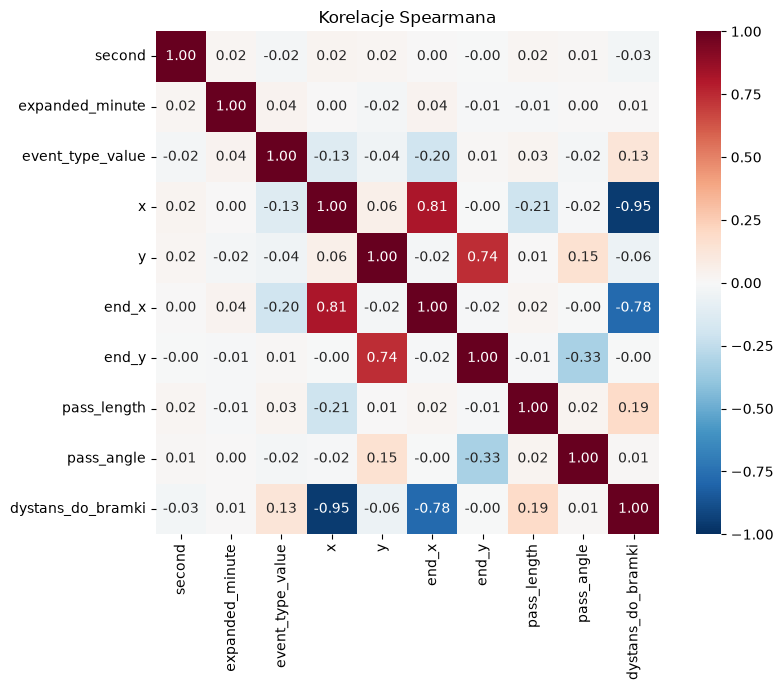

najsilniejsze pary:
  x                        <-> dystans_do_bramki        r = -0.955
  x                        <-> end_x                    r = +0.814
  end_x                    <-> dystans_do_bramki        r = -0.777
  y                        <-> end_y                    r = +0.738
  end_y                    <-> pass_angle               r = -0.325
  x                        <-> pass_length              r = -0.209
  event_type_value         <-> end_x                    r = -0.201
  pass_length              <-> dystans_do_bramki        r = +0.193

UWAGA: zwiazki z 'dystans_do_bramki' wynikaja z geometrii -
dystans jest wyliczany z x i y, wiec korelacja jest z definicji.


In [6]:
# Macierz korelacji Spearmana miedzy wybranymi kolumnami (wszystkie mecze)
korelacje = events_all[wybrane].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Korelacje Spearmana")
plt.tight_layout()
plt.savefig(FIGURY / "korelacje.png", dpi=130)
plt.show()

pary = []
for a, b in itertools.combinations(wybrane, 2):
    pary.append((a, b, korelacje.loc[a, b]))
pary.sort(key=lambda t: -abs(t[2]))

print("najsilniejsze pary:")
for a, b, r in pary[:8]:
    print(f"  {a:<24} <-> {b:<24} r = {r:+.3f}")
print()
print("UWAGA: zwiazki z 'dystans_do_bramki' wynikaja z geometrii -")
print("dystans jest wyliczany z x i y, wiec korelacja jest z definicji.")


## 5. Ranking trójek (R² płaszczyzny)

Dla każdej trójki kolumn dopasowujemy płaszczyznę najmniejszych kwadratów — sprawdzamy trzy możliwe kierunki i bierzemy najlepszy R². Ranking + podsumowanie wizualne par i trójek.


In [7]:
# Ranking trojek na wszystkich meczach: dla kazdej trojki dopasowujemy plaszczyzne.
# Funkcja r2_plaszczyzny jest zdefiniowana w sekcji 1.
wyniki = []
for a, b, c in itertools.combinations(wybrane, 3):
    dane = events_all[[a, b, c]].dropna()
    if len(dane) < 50:
        continue

    # sprawdzamy wszystkie trzy kierunki, bierzemy najlepszy
    najlepsze = (0.0, c, a, b)
    for cel in (a, b, c):
        reszta = [k for k in (a, b, c) if k != cel]
        r2 = r2_plaszczyzny(dane, reszta[0], reszta[1], cel)
        if r2 > najlepsze[0]:
            najlepsze = (r2, cel, reszta[0], reszta[1])

    wyniki.append(najlepsze)

wyniki.sort(key=lambda t: -t[0])

print(f"sprawdzono trojek: {len(wyniki)}")
print()
print("TOP 10:")
for r2, cel, x1, x2 in wyniki[:10]:
    print(f"  {cel:<24} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")
print()
print("UWAGA: trojki z 'dystans_do_bramki' sa zalezne geometrycznie od x i y -")
print("R2 ~ 0.89 wynika z definicji dystansu, nie z gry.")


sprawdzono trojek: 120

TOP 10:
  dystans_do_bramki        ~ x                      + y                      R2 = 0.8904
  dystans_do_bramki        ~ second                 + x                      R2 = 0.8898
  dystans_do_bramki        ~ expanded_minute        + x                      R2 = 0.8898
  x                        ~ event_type_value       + dystans_do_bramki      R2 = 0.8897
  x                        ~ end_x                  + dystans_do_bramki      R2 = 0.8817
  dystans_do_bramki        ~ x                      + pass_length            R2 = 0.8571
  x                        ~ end_y                  + dystans_do_bramki      R2 = 0.8566
  x                        ~ pass_angle             + dystans_do_bramki      R2 = 0.8566
  x                        ~ end_x                  + pass_length            R2 = 0.7713
  end_y                    ~ y                      + pass_angle             R2 = 0.7670

UWAGA: trojki z 'dystans_do_bramki' sa zalezne geometrycznie od x i y -
R2 ~ 

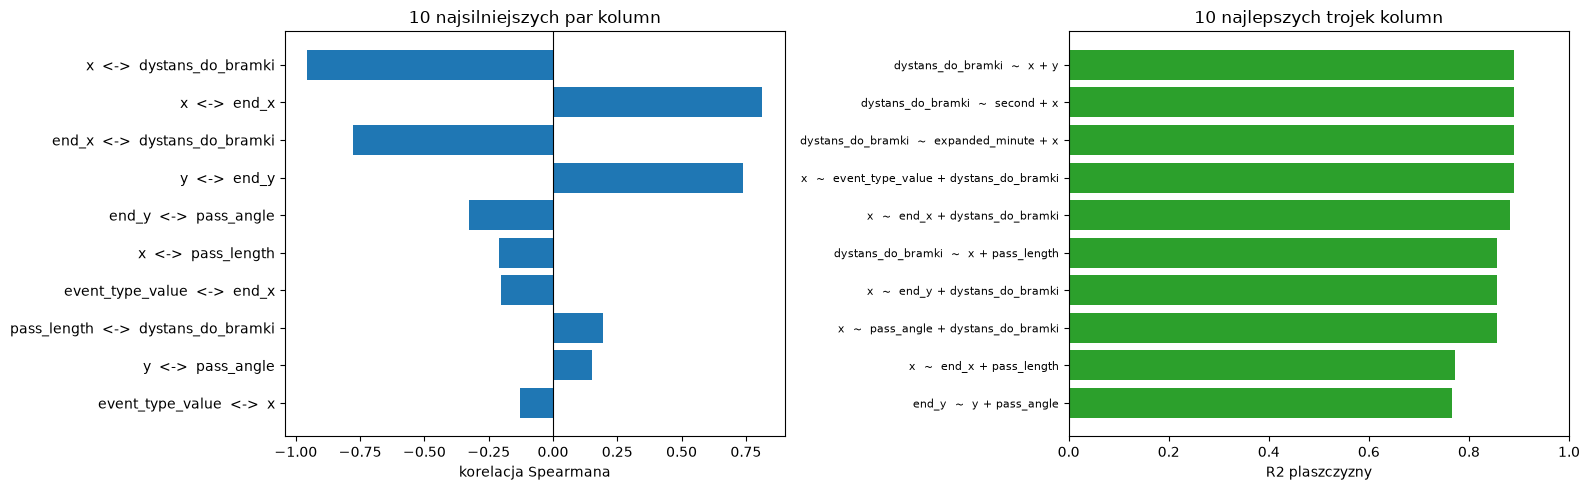

In [8]:
# Podsumowanie wizualne sekcji 4 i 5: najsilniejsze pary i najlepsze trojki obok siebie
fig, (lewy, prawy) = plt.subplots(1, 2, figsize=(16, 5))

# --- lewy panel: pary ---
top_pary = pary[:10]
lewy.barh(
    [f"{a}  <->  {b}" for a, b, _ in top_pary][::-1],
    [r for _, _, r in top_pary][::-1],
)
lewy.axvline(0, color="black", linewidth=0.8)
lewy.set_xlabel("korelacja Spearmana")
lewy.set_title("10 najsilniejszych par kolumn")

# --- prawy panel: trojki ---
top_trojki = wyniki[:10]
prawy.barh(
    [f"{cel}  ~  {x1} + {x2}" for r2, cel, x1, x2 in top_trojki][::-1],
    [r2 for r2, _, _, _ in top_trojki][::-1],
    color="tab:green",
)
prawy.set_xlabel("R2 plaszczyzny")
prawy.set_title("10 najlepszych trojek kolumn")
prawy.set_xlim(0, 1)
prawy.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(FIGURY / "pary_i_trojki.png", dpi=130)
plt.show()


## 6. Wykresy 3D

Cztery najlepsze trójki: punkty + dopasowana płaszczyzna.


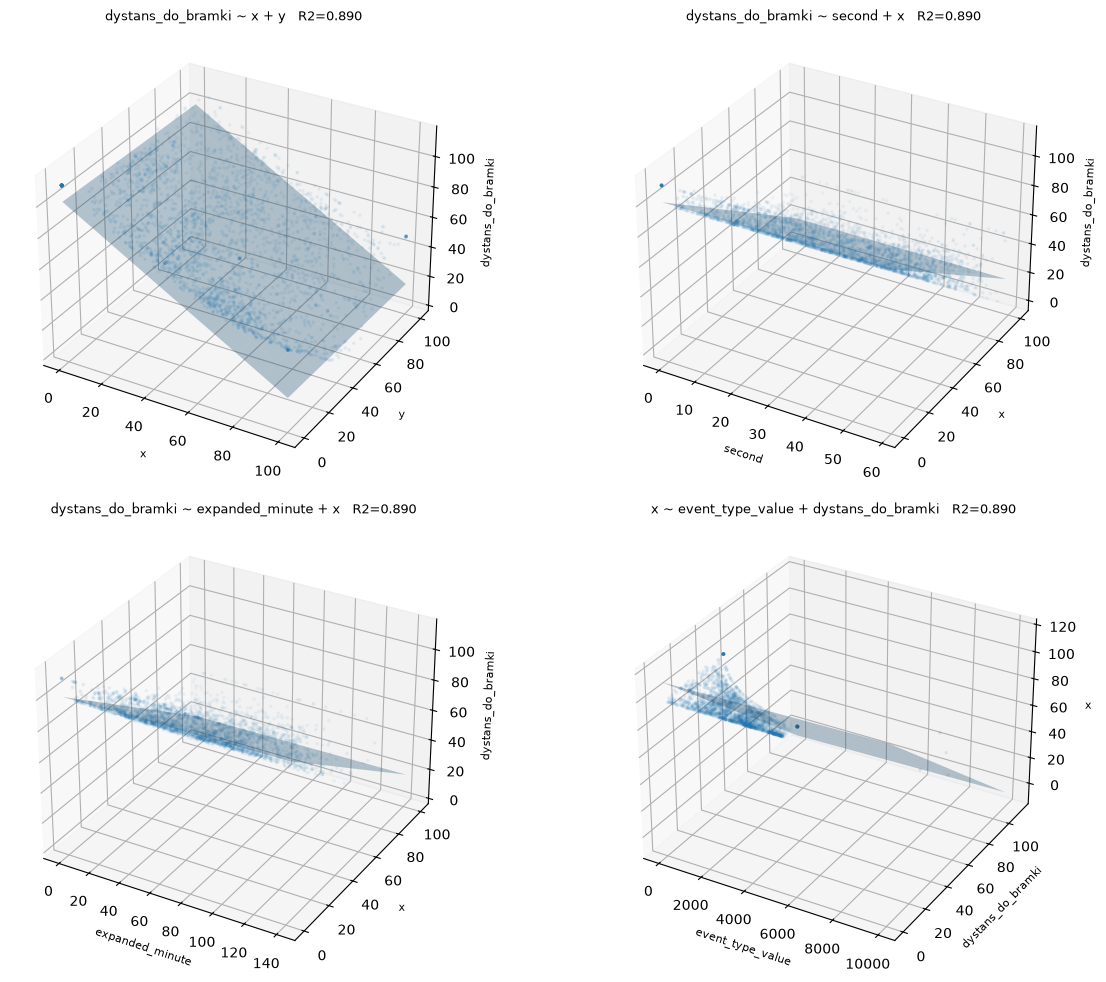

In [9]:
# Cztery najlepsze trojki na jednej figurze 2x2 - punkty + dopasowana plaszczyzna
# Regresja liczona na WSZYSTKICH punktach, do rysowania probka (16 tys. punktow to plama).
PROBKA = 2500

fig = plt.figure(figsize=(13, 10))

for nr, (r2, cel, x1, x2) in enumerate(wyniki[:4], start=1):
    dane = events_all[[x1, x2, cel]].dropna()

    # dopasowanie na pelnych danych
    X = np.column_stack([np.ones(len(dane)), dane[x1], dane[x2]])
    beta, *_ = np.linalg.lstsq(X, dane[cel].to_numpy(), rcond=None)

    ax = fig.add_subplot(2, 2, nr, projection="3d")

    # rysowanie na probce
    probka = dane.sample(min(PROBKA, len(dane)), random_state=42)
    ax.scatter(probka[x1], probka[x2], probka[cel], s=3, alpha=0.3)

    xs = np.linspace(dane[x1].min(), dane[x1].max(), 10)
    ys = np.linspace(dane[x2].min(), dane[x2].max(), 10)
    siatka_x, siatka_y = np.meshgrid(xs, ys)
    siatka_z = beta[0] + beta[1] * siatka_x + beta[2] * siatka_y
    ax.plot_surface(siatka_x, siatka_y, siatka_z, alpha=0.3)

    ax.set_xlabel(x1, fontsize=8)
    ax.set_ylabel(x2, fontsize=8)
    ax.set_zlabel(cel, fontsize=8)
    ax.set_title(f"{cel} ~ {x1} + {x2}   R2={r2:.3f}", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURY / "trojki_3d.png", dpi=110)
plt.show()


## 7. Rekonstrukcja posiadania

Posiadanie = ciąg kolejnych zdarzeń tej samej drużyny w tym samym meczu. Bez serii rzutów karnych (period 5) i zdarzeń przed/po meczu.


In [10]:
# Rekonstrukcja posiadania na wszystkich meczach (poziom analizy, na ktorym dane maja sens).
ev = events_all.copy()
ev = ev.sort_values(["match_id", "event_index"]).reset_index(drop=True)

# bez serii rzutow karnych (period 5) i bez zdarzen przed/po meczu (14, 16)
przed = len(ev)
ev = ev[~ev["period_value"].isin([5, 14, 16])]
ev = ev[ev["team_id"].notna()]
print(f"zdarzen po odfiltrowaniu: {len(ev)} (usunieto {przed - len(ev)})")
print()

ev["gol"] = ev["is_goal"] == True
ev["strzal"] = ev["is_shot"] == True
ev["podanie"] = ev["event_type"] == "Pass"

# posiadanie = ciag kolejnych zdarzen tej samej druzyny W TYM SAMYM MECZU.
# Warunek na match_id jest konieczny - inaczej ostatni event meczu A klei sie
# z pierwszym eventem meczu B.
zmiana_druzyny = ev["team_id"] != ev["team_id"].shift()
zmiana_meczu = ev["match_id"] != ev["match_id"].shift()
ev["posiadanie"] = (zmiana_druzyny | zmiana_meczu).cumsum()

# pole karne: x >= 83 ORAZ y w [21, 79]; bez zdarzen strzalu (zeby uniknac tautologii)
ev["w_polu"] = (ev["x"] >= 83) & (ev["y"].between(21, 79))
ev["wejscie"] = ev["w_polu"] & (~ev["strzal"])

posiadania = ev.groupby(["match_id", "posiadanie"]).agg(
    zdarzen=("event_index", "size"),
    podan=("podanie", "sum"),
    start_x=("x", "first"),
    wejscie=("wejscie", "max"),
    strzal=("strzal", "max"),
    gol=("gol", "max"),
).reset_index()

print("posiadan:", len(posiadania))
print("ze strzalem:", int(posiadania["strzal"].sum()))
print("z golem:", int(posiadania["gol"].sum()))
print()
print(f"P(strzal | posiadanie) = {100 * posiadania['strzal'].mean():.2f}%")
print(f"P(gol    | posiadanie) = {100 * posiadania['gol'].mean():.2f}%")


zdarzen po odfiltrowaniu: 16184 (usunieto 65)

posiadan: 5074
ze strzalem: 262
z golem: 36

P(strzal | posiadanie) = 5.16%
P(gol    | posiadanie) = 0.71%


## 8. Co zwiększa szansę na strzał

Prawdopodobieństwa warunkowe z 95% przedziałami ufności Wilsona.


In [11]:
# Warunkowe prawdopodobienstwa P(strzal | cecha posiadania)
# Funkcje wilson() i tabela() sa zdefiniowane w sekcji 1.
posiadania["podan_bin"] = pd.cut(posiadania["podan"], [-1, 0, 1, 2, 4, 8, 100],
                                 labels=["0", "1", "2", "3-4", "5-8", "9+"])
posiadania["strefa"] = pd.cut(posiadania["start_x"], [0, 33, 66, 100],
                              labels=["wlasna", "srodek", "ataku"])

for kolumna in ["wejscie", "podan_bin", "strefa"]:
    print(f"=== P(strzal) wg {kolumna} ===")
    print(tabela(posiadania, kolumna).to_string())
    print()


=== P(strzal) wg wejscie ===
         przypadkow  trafien    P %    95% CI
wejscie                                      
False          4625      211   4.56   4.0-5.2
True            449       51  11.36  8.7-14.6

=== P(strzal) wg podan_bin ===
           przypadkow  trafien   P %    95% CI
podan_bin                                     
0                2378      105  4.42   3.7-5.3
1                 993       45  4.53   3.4-6.0
2                 456       21  4.61   3.0-6.9
3-4               486       30  6.17   4.4-8.7
5-8               435       33  7.59  5.5-10.5
9+                326       28  8.59  6.0-12.1

=== P(strzal) wg strefa ===
        przypadkow  trafien    P %     95% CI
strefa                                       
wlasna        1977       30   1.52    1.1-2.2
srodek        1848       55   2.98    2.3-3.9
ataku         1129      176  15.59  13.6-17.8



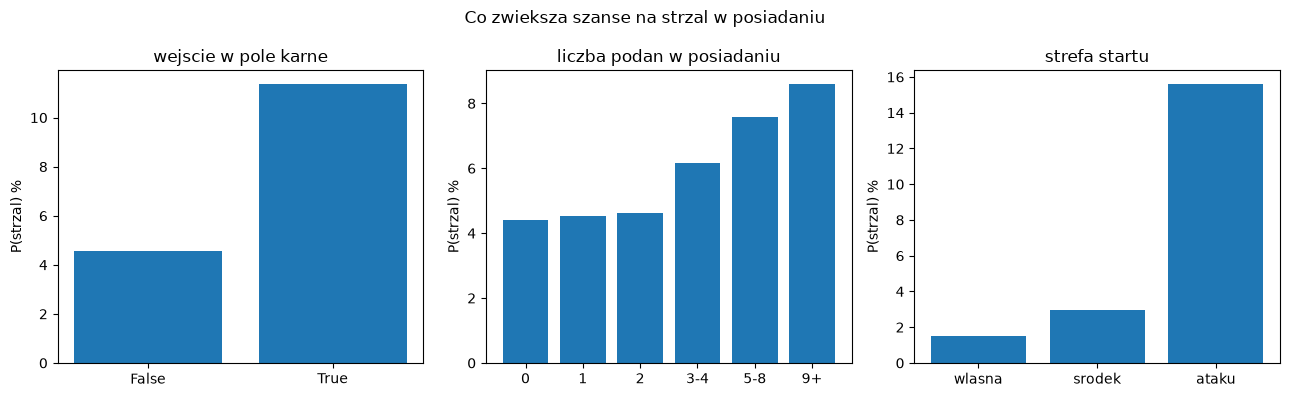

In [12]:
# Trzy panele: co zwieksza szanse na strzal
fig, osie = plt.subplots(1, 3, figsize=(13, 4))

for os_, kolumna, tytul in [
    (osie[0], "wejscie", "wejscie w pole karne"),
    (osie[1], "podan_bin", "liczba podan w posiadaniu"),
    (osie[2], "strefa", "strefa startu"),
]:
    t = tabela(posiadania, kolumna)
    os_.bar([str(i) for i in t.index], t["P %"])
    os_.set_title(tytul)
    os_.set_ylabel("P(strzal) %")

plt.suptitle("Co zwieksza szanse na strzal w posiadaniu")
plt.tight_layout()
plt.savefig(FIGURY / "posiadanie_strzal.png", dpi=130)
plt.show()


## 9. Które podania kończą się strzałem

Analiza na poziomie pojedynczego podania: strefa zakończenia i typ podania.


In [13]:
# Poziom podania: ktore podania koncza sie strzalem w tej samej akcji
ev["idx_strzal"] = ev["event_index"].where(ev["strzal"])
ev["idx_strzal"] = ev.groupby(["match_id", "posiadanie"])["idx_strzal"].transform("max")

podania = ev[ev["podanie"] & (ev["outcome_type"] == "Successful")].copy()
podania["potem_strzal"] = podania["idx_strzal"] > podania["event_index"]

podania["koniec"] = pd.cut(podania["end_x"], [0, 33, 66, 83, 100],
                           labels=["wlasna", "srodek", "3 tercja", "pole karne"])

print("podan celnych:", len(podania))
print("z nich konczy sie strzalem:", int(podania["potem_strzal"].sum()))
print(f"bazowo: {100 * podania['potem_strzal'].mean():.2f}%")
print()
print("=== wg strefy, w ktorej konczy sie podanie ===")
print(tabela(podania, "koniec", cel="potem_strzal").to_string())
print()
print("=== wg typu podania ===")
for kolumna in ["is_through_ball", "is_cross"]:
    print(f"-- {kolumna}")
    print(tabela(podania, kolumna, cel="potem_strzal").to_string())
    print()


podan celnych: 8887
z nich konczy sie strzalem: 743
bazowo: 8.36%

=== wg strefy, w ktorej konczy sie podanie ===
            przypadkow  trafien    P %     95% CI
koniec                                           
wlasna            2283      111   4.86    4.1-5.8
srodek            4444      281   6.32    5.6-7.1
3 tercja          1629      215  13.20  11.6-14.9
pole karne         531      136  25.61  22.1-29.5

=== wg typu podania ===
-- is_through_ball
                 przypadkow  trafien    P %     95% CI
is_through_ball                                       
False                  8866      732   8.26    7.7-8.8
True                     21       11  52.38  32.4-71.7

-- is_cross
          przypadkow  trafien    P %     95% CI
is_cross                                       
False           8825      713   8.08    7.5-8.7
True              62       30  48.39  36.4-60.6



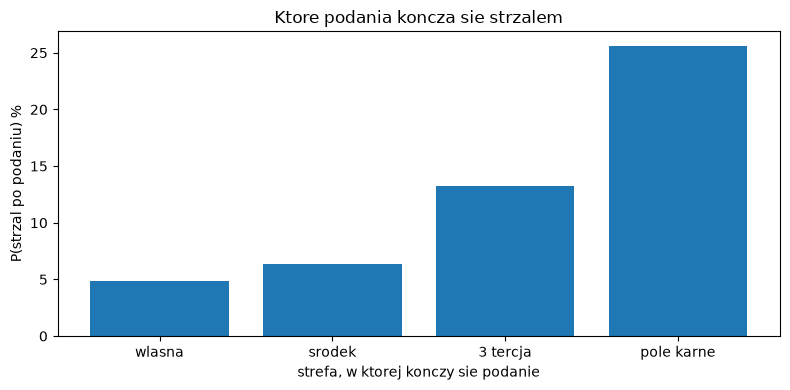

liczebnosci:
            przypadkow  trafien
koniec                         
wlasna            2283      111
srodek            4444      281
3 tercja          1629      215
pole karne         531      136


In [14]:
# Wykres: P(strzal po podaniu) wg strefy zakonczenia podania
t = tabela(podania, "koniec", cel="potem_strzal")

plt.figure(figsize=(8, 4))
plt.bar([str(i) for i in t.index], t["P %"])
plt.ylabel("P(strzal po podaniu) %")
plt.xlabel("strefa, w ktorej konczy sie podanie")
plt.title("Ktore podania koncza sie strzalem")
plt.tight_layout()
plt.savefig(FIGURY / "podania_strzal.png", dpi=130)
plt.show()

print("liczebnosci:")
print(t[["przypadkow", "trafien"]].to_string())


## 10. Pozycje z formacji

Ustawienie wyjściowe obu drużyn z tabeli `formations` (skala 0–10 przeskalowana do 0–100). Uwaga na osie: w tej tabeli wzdłuż boiska idzie `vertical` (0 = własna bramka), a `horizontal` to szerokość — odwrotnie niż w zdarzeniach, gdzie wzdłuż boiska idzie `x`.


formacje w meczu: [ 343  352 4231]
zawodnikow w ustawieniu wyjsciowym: 22


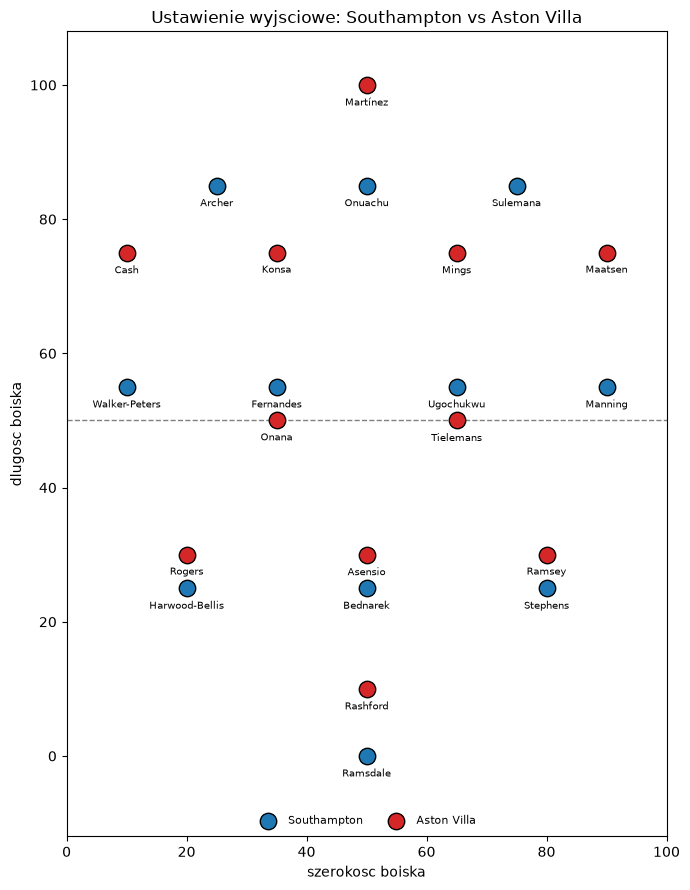

In [15]:
# Pozycje z formacji - ustawienie wyjsciowe obu druzyn (jeden mecz, tabela 'formations' z sekcji 1)
start = formations[formations["start_minute_expanded"] == 0]

print("formacje w meczu:", formations["formation_name"].unique())
print("zawodnikow w ustawieniu wyjsciowym:", len(start))

fig, ax = plt.subplots(figsize=(7, 9))
kolory = {"home": "tab:blue", "away": "tab:red"}

for side in ["home", "away"]:
    d = start[start["team_side"] == side]

    # horizontal i vertical sa w skali 0-10 -> mnozymy przez 10
    xs = d["horizontal"] * 10
    ys = d["vertical"] * 10
    if side == "away":
        ys = 100 - ys  # lustro, zeby druzyny graly naprzeciw siebie

    # puste punkty tylko po to, zeby legenda miala co pokazac
    ax.scatter([], [], s=140, c=kolory[side], edgecolors="black", label=d["team_name"].iloc[0])
    ax.scatter(xs, ys, s=140, c=kolory[side], edgecolors="black", zorder=3)

    for x, y, nazwa in zip(xs, ys, d["player_name"]):
        # podpis POD punktem, inaczej nazwisko zaslania znacznik
        ax.annotate(
            nazwa.split()[-1],
            (x, y),
            fontsize=7,
            ha="center",
            va="top",
            xytext=(0, -9),
            textcoords="offset points",
            zorder=4,
        )

ax.axhline(50, color="gray", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_ylim(-12, 108)
ax.set_xlabel("szerokosc boiska")
ax.set_ylabel("dlugosc boiska")
ax.set_title("Ustawienie wyjsciowe: " + " vs ".join(start["team_name"].unique()))
ax.legend(loc="lower center", ncols=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURY / "formacje.png", dpi=130)
plt.show()


## 11. Momentum drużyny

`team_stats` per minuta: narastające dotknięcia i podania oraz przewaga w oknach 5-minutowych.


metryki w team_stats: 35
stat_name
ratings           191
touches           181
possession        149
passSuccess       143
passesTotal       143
passesAccurate    130



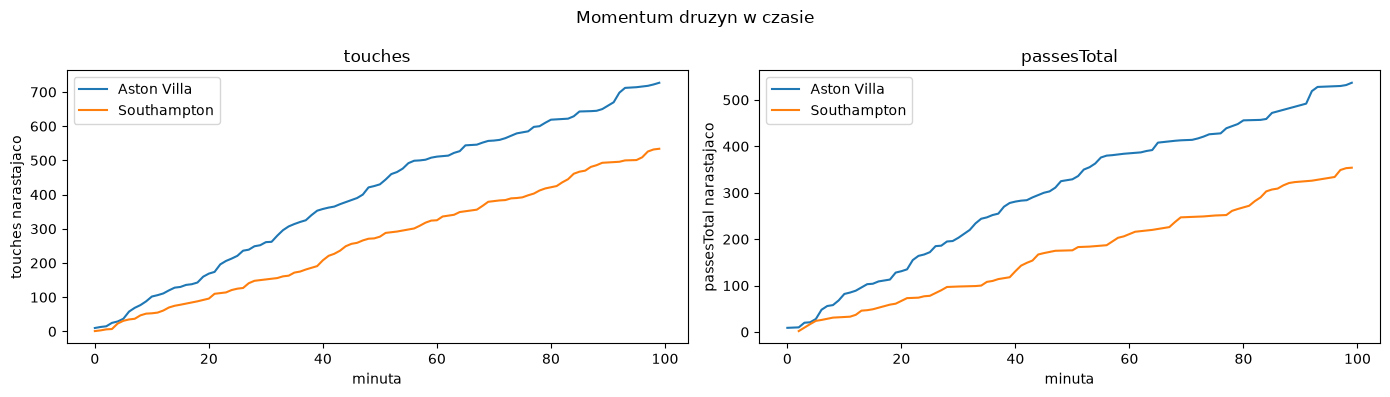

In [16]:
# Momentum druzyn: narastajace dotkniecia i podania na jednej figurze
print("metryki w team_stats:", team_stats["stat_name"].nunique())
print(team_stats["stat_name"].value_counts().head(6).to_string())
print()

# UWAGA: touches i passesTotal to PRZYROSTY na minute -> cumsum().
# 'ratings' to wartosc narastajaca (snapshot) - tego nie sumujemy.
fig, osie = plt.subplots(1, 2, figsize=(14, 4))

for os_, metryka in zip(osie, ["touches", "passesTotal"]):
    for nazwa, d in team_stats[team_stats["stat_name"] == metryka].groupby("team_name"):
        d = d.sort_values("minute")
        os_.plot(d["minute"], d["value"].cumsum(), label=nazwa)

    os_.set_xlabel("minuta")
    os_.set_ylabel(metryka + " narastajaco")
    os_.set_title(metryka)
    os_.legend()

plt.suptitle("Momentum druzyn w czasie")
plt.tight_layout()
plt.savefig(FIGURY / "momentum.png", dpi=120)
plt.show()


In [17]:
# Okna 5-minutowe: kto mial przewage w danym fragmencie meczu
okna = team_stats[team_stats["stat_name"] == "touches"].copy()
okna["okno"] = (okna["minute"] // 5) * 5

tabela_okien = okna.groupby(["okno", "team_name"])["value"].sum().unstack()

print("dotkniecia pilki w oknach 5-minutowych:")
print(tabela_okien.head(12).to_string())

if tabela_okien.shape[1] == 2:
    roznica = tabela_okien.iloc[:, 0] - tabela_okien.iloc[:, 1]
    print()
    print("przewaga (", tabela_okien.columns[0], "-", tabela_okien.columns[1], "):")
    print(roznica.head(12).to_string())


dotkniecia pilki w oknach 5-minutowych:
team_name  Aston Villa  Southampton
okno                               
0                 29.0         23.0
5                 59.0         29.0
10                40.0         23.0
15                32.0         17.0
20                53.0         29.0
25                39.0         29.0
30                55.0         13.0
35                46.0         28.0
40                19.0         58.0
45                53.0         23.0
50                51.0         23.0
55                32.0         29.0

przewaga ( Aston Villa - Southampton ):
okno
0      6.0
5     30.0
10    17.0
15    15.0
20    24.0
25    10.0
30    42.0
35    18.0
40   -39.0
45    30.0
50    28.0
55     3.0


## 12. Rzuty karne

`is_penalty` flaguje całą sytuację (faul, kartka, `PenaltyFaced`), nie sam strzał. Sekwencje przed karnym.


In [18]:
# Rzuty karne - UWAGA: is_penalty to flaga CALEJ SYTUACJI, nie strzal z karnego.
# Flaga obejmuje faul, kartke i PenaltyFaced bramkarza.
karny_strzal = ev[ev["is_penalty"] & ev["strzal"]]

print("zdarzen z flaga is_penalty:", int(ev["is_penalty"].sum()))
print("z tego strzalow z karnego :", len(karny_strzal))
print("z tego goli               :", int(karny_strzal["gol"].sum()))
print()

ile_na_mecz = karny_strzal.groupby("match_id").size()
print("meczow z rzutem karnym:", len(ile_na_mecz), "z", ev["match_id"].nunique())
print(ile_na_mecz.to_string())


zdarzen z flaga is_penalty: 26
z tego strzalow z karnego : 6
z tego goli               : 4

meczow z rzutem karnym: 5 z 10
match_id
1821123    2
1993983    1
1995426    1
2002449    1
2029242    1


In [19]:
# Co poprzedza strzal z karnego - 4 zdarzenia wstecz
print("=== sekwencja przed kazdym strzalem z karnego ===")

for _, k in karny_strzal.iterrows():
    biezacy = ev[
        (ev["match_id"] == k["match_id"])
        & (ev["event_index"] < k["event_index"])
        & (ev["event_index"] >= k["event_index"] - 4)
    ]

    print()
    print(f"mecz {k['match_id']}, {k['expanded_minute']}. min - karny: {k['player_name']} ({k['team_name']})")

    for _, z in biezacy.iterrows():
        gracz = z["player_name"] if pd.notna(z["player_name"]) else "-"
        print(f"   {z['expanded_minute']:>3}. min  {str(z['event_type']):<16} {gracz}")


=== sekwencja przed kazdym strzalem z karnego ===

mecz 1821123, 70. min - karny: Marco Asensio (Aston Villa)
    69. min  Foul             Ollie Watkins
    69. min  Foul             Jan Bednarek
    69. min  Card             Jan Bednarek
    70. min  PenaltyFaced     Aaron Ramsdale

mecz 1821123, 95. min - karny: Marco Asensio (Aston Villa)
    93. min  BallTouch        Donyell Malen
    93. min  Foul             John McGinn
    93. min  Foul             Jack Stephens
    95. min  PenaltyFaced     Aaron Ramsdale

mecz 1993983, 10. min - karny: Kylian Mbappé (Real Madrid)
     9. min  Pass             Yan Diomande
     9. min  TakeOn           Kylian Mbappé
     9. min  Foul             Kylian Mbappé
     9. min  Foul             Matteo Prati

mecz 1995426, 65. min - karny: Niclas Füllkrug (Werder Bremen)
    64. min  Pass             Mitchell Weiser
    65. min  SavedShot        Olivier Deman
    65. min  Foul             -
    65. min  Foul             Laurin Curda

mecz 2002449, 21

## 13. Big chance

Prawdopodobieństwo stuprocentowej sytuacji w zależności od cech posiadania.


In [20]:
# BIG CHANCE - doklejenie do posiadan (razem z czasem trwania)
dodatek = ev.groupby(["match_id", "posiadanie"]).agg(
    big_chance=("is_big_chance", "max"),
    czas=("expanded_minute", lambda s: s.max() - s.min()),
).reset_index()

posiadania = posiadania.merge(dodatek, on=["match_id", "posiadanie"], how="left")

print("big chance w zbiorze zdarzen:", int(ev["is_big_chance"].sum()))
print("posiadan z big chance      :", int(posiadania["big_chance"].sum()))
print()

for kolumna in ["wejscie", "podan_bin", "strefa"]:
    print(f"=== P(big chance) wg {kolumna} ===")
    print(tabela(posiadania, kolumna, cel="big_chance").to_string())
    print()


big chance w zbiorze zdarzen: 49
posiadan z big chance      : 49

=== P(big chance) wg wejscie ===
         przypadkow  trafien   P %   95% CI
wejscie                                    
False          4625       37  0.80  0.6-1.1
True            449       12  2.67  1.5-4.6

=== P(big chance) wg podan_bin ===
           przypadkow  trafien   P %   95% CI
podan_bin                                    
0                2378       19  0.80  0.5-1.2
1                 993        7  0.70  0.3-1.4
2                 456        6  1.32  0.6-2.8
3-4               486        3  0.62  0.2-1.8
5-8               435        8  1.84  0.9-3.6
9+                326        6  1.84  0.8-4.0

=== P(big chance) wg strefa ===
        przypadkow  trafien   P %   95% CI
strefa                                    
wlasna        1977        4  0.20  0.1-0.5
srodek        1848       17  0.92  0.6-1.5
ataku         1129       28  2.48  1.7-3.6



## 14. Ranking cech per cel

Osobny ranking par cech dla każdego celu: strzał, gol, big chance.


In [21]:
# Ranking par cech dla KAZDEGO celu osobno (poziom posiadania).
# Funkcja r2_plaszczyzny jest zdefiniowana w sekcji 1.
cechy_posiadania = ["podan", "zdarzen", "start_x", "czas", "wejscie"]
cele_posiadania = ["strzal", "gol", "big_chance"]

for cel in cele_posiadania:
    pary = []

    for x1, x2 in itertools.combinations([k for k in cechy_posiadania if k != cel], 2):
        dane = posiadania[[x1, x2, cel]].dropna()
        if len(dane) < 50:
            continue
        pary.append((r2_plaszczyzny(dane, x1, x2, cel), x1, x2))

    pary.sort(key=lambda t: -t[0])

    print(f"=== TOP 3 pary cech dla celu '{cel}' (posiadan: {len(posiadania)}) ===")
    for r2, x1, x2 in pary[:3]:
        print(f"  {cel:<12} ~ {x1:<10} + {x2:<10} R2 = {r2:.4f}")
    print()


=== TOP 3 pary cech dla celu 'strzal' (posiadan: 5074) ===
  strzal       ~ zdarzen    + start_x    R2 = 0.0606
  strzal       ~ start_x    + czas       R2 = 0.0568
  strzal       ~ podan      + start_x    R2 = 0.0542

=== TOP 3 pary cech dla celu 'gol' (posiadan: 5074) ===
  gol          ~ start_x    + czas       R2 = 0.0104
  gol          ~ zdarzen    + start_x    R2 = 0.0092
  gol          ~ podan      + zdarzen    R2 = 0.0077

=== TOP 3 pary cech dla celu 'big_chance' (posiadan: 5074) ===
  big_chance   ~ zdarzen    + start_x    R2 = 0.0124
  big_chance   ~ podan      + zdarzen    R2 = 0.0107
  big_chance   ~ start_x    + czas       R2 = 0.0101



## Ograniczenia


**Czołowe trójki są geometryczne i zaśmiecone licznikami.** `dystans_do_bramki` jest wyliczony
z `x` i `y`, więc `dystans ~ x + y` daje R² = 0,89 z definicji. Podobnie `x ↔ end_x` (r = 0,81) —
pozycja końcowa podania leży blisko startowej. W rankingu są też `second` (sekunda w minucie)
i `event_type_value` (kod typu zdarzenia): to liczniki, nie cechy gry, więc ich miejsca w TOP-10
nic nie znaczą. Całość traktuj jako rozpoznanie danych, nie wynik.